In [11]:
import os
import numpy as np
import pandas as pd
import kagglehub

In [12]:
# 1. Ingest Data via KaggleHub API with Local Fallback
try:
    path = kagglehub.dataset_download(
        "saurabhbadole/zomato-delivery-operations-analytics-dataset"
    )
    csv_file = os.path.join(path, "Zomato Dataset.csv")
    df_raw = pd.read_csv(csv_file)
    print("Dataset successfully loaded from: %s\n" % csv_file)
except Exception as e:
    print("KaggleHub loading failed (%s). Attempting local fallback..." % e)
    df_raw = pd.read_csv("Zomato Dataset.csv")

Dataset successfully loaded from: C:\Users\ngame.NGAME\.cache\kagglehub\datasets\saurabhbadole\zomato-delivery-operations-analytics-dataset\versions\1\Zomato Dataset.csv



In [13]:
# 2.Statistical Summary Function
def summarize_dataset_all(df):
    print("DATASET OVERVIEW: %d Rows | %d Columns" % (df.shape[0], df.shape[1]))
    
    # Overview Table
    summary = pd.DataFrame({
        "Data_Type": df.dtypes,
        "Non_Null_Count": df.notnull().sum(),
        "Missing_Count": df.isnull().sum(),
        "Missing_Pct (%)": (df.isnull().sum() / len(df) * 100).round(2),
        "Unique_Values": df.nunique(),
        "Sample_Value": [df[col].dropna().iloc[0] if not df[col].dropna().empty else np.nan for col in df.columns]
    })
    
    # Full Statistical Description
    full_describe = df.describe(include="all").T
    
    return summary, full_describe



In [14]:
# Detailed Summaries
summary_table, full_stats = summarize_dataset_all(df_raw)
print("1. Column Health & Null Audit")
display(summary_table)

print("\n2. Full Feature Describe (Numeric & Categorical)")
display(full_stats)

DATASET OVERVIEW: 45584 Rows | 20 Columns
1. Column Health & Null Audit


,Data_Type,Non_Null_Count,Missing_Count,Missing_Pct (%),Unique_Values,Sample_Value
ID,object,45584,0,0.00,45584,0xcdcd
Delivery_person_ID,object,45584,0,0.00,1320,DEHRES17DEL01
Delivery_person_Age,float64,43730,1854,4.07,22,36.0
Delivery_person_Ratings,float64,43676,1908,4.19,28,4.2
Restaurant_latitude,float64,45584,0,0.00,657,30.327968
Restaurant_longitude,float64,45584,0,0.00,518,78.046106
Delivery_location_latitude,float64,45584,0,0.00,4373,30.397968
Delivery_location_longitude,float64,45584,0,0.00,4373,78.116106
Order_Date,object,45584,0,0.00,44,12-02-2022
Time_Orderd,object,43853,1731,3.80,176,21:55



2. Full Feature Describe (Numeric & Categorical)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,45584,45584,0xcdcd,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_ID,45584,1320,JAPRES11DEL02,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Age,43730.0,NaN,NaN,NaN,29.566911,5.815064,15.0,25.0,30.0,35.0,50.0
Delivery_person_Ratings,43676.0,NaN,NaN,NaN,4.633774,0.334744,1.0,4.5,4.7,4.9,6.0
Restaurant_latitude,45584.0,NaN,NaN,NaN,17.017948,8.185674,-30.905562,12.933284,18.55144,22.728163,30.914057
Restaurant_longitude,45584.0,NaN,NaN,NaN,70.229684,22.885575,-88.366217,73.17,75.897963,78.044095,88.433452
Delivery_location_latitude,45584.0,NaN,NaN,NaN,17.46548,7.335562,0.01,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45584.0,NaN,NaN,NaN,70.844161,21.120578,0.01,73.28,76.002574,78.107044,88.563452
Order_Date,45584,44,15-03-2022,1192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_Orderd,43853,176,21:55,461,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
#inspection
# 1. Inspect exact distribution of Ratings == 6.0
rating_6_count = (df_raw["Delivery_person_Ratings"] == 6.0).sum()
print("Total rows with Rating == 6.0: %d (%.2f%%)" % 
      (rating_6_count, rating_6_count / len(df_raw) * 100))

# 2. Inspect invalid GPS coordinate counts
invalid_gps = df_raw[
    (df_raw["Restaurant_latitude"] <= 0) | 
    (df_raw["Restaurant_longitude"] <= 0) | 
    (df_raw["Delivery_location_latitude"] <= 0) | 
    (df_raw["Delivery_location_longitude"] <= 0)
]
print("Total rows with Invalid GPS (<= 0): %d (%.2f%%)" % 
      (len(invalid_gps), len(invalid_gps) / len(df_raw) * 100))

# 3. Inspect Driver Age < 18 counts
underage_count = (df_raw["Delivery_person_Age"] < 18).sum()
print("Total rows with Driver Age < 18: %d (%.2f%%)" % 
      (underage_count, underage_count / len(df_raw) * 100))

# 4. Check overlap of missing values across rows
rows_with_any_null = df_raw.isnull().any(axis=1).sum()
print("Total rows with AT LEAST ONE missing value: %d (%.2f%%)" % 
      (rows_with_any_null, rows_with_any_null / len(df_raw) * 100))





Total rows with Rating == 6.0: 53 (0.12%)
Total rows with Invalid GPS (<= 0): 4071 (8.93%)
Total rows with Driver Age < 18: 38 (0.08%)
Total rows with AT LEAST ONE missing value: 4225 (9.27%)


In [16]:
# Create working copy
df_clean = df_raw.copy()

In [17]:
## #after inspecion, handle the that ano anomalies (true part)
## and do extract hour (8) and encoding (9)

# 1. Clean working copy
df_clean = df_raw.copy()

# 2. Strip whitespace across all text columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 3. Cap Ratings > 5.0 at 5.0
df_clean.loc[df_clean["Delivery_person_Ratings"] > 5.0, "Delivery_person_Ratings"] = 5.0

# 4. Filter Invalid GPS Coordinates and Underage Drivers (< 18)
valid_mask = (
    (df_clean["Restaurant_latitude"] > 0) &
    (df_clean["Restaurant_longitude"] > 0) &
    (df_clean["Delivery_location_latitude"] > 0) &
    (df_clean["Delivery_location_longitude"] > 0) &
    (df_clean["Delivery_person_Age"] >= 18)
)
df_clean = df_clean[valid_mask].copy()

# 5. Direct assignment for fillna and replace
df_clean["Delivery_person_Age"] = df_clean["Delivery_person_Age"].fillna(df_clean["Delivery_person_Age"].median())
df_clean["Delivery_person_Ratings"] = df_clean["Delivery_person_Ratings"].fillna(df_clean["Delivery_person_Ratings"].median())
df_clean["multiple_deliveries"] = df_clean["multiple_deliveries"].fillna(df_clean["multiple_deliveries"].median())

for cat_col in ["Weather_conditions", "Road_traffic_density", "City", "Festival"]:
    df_clean[cat_col] = df_clean[cat_col].replace(["nan", "NaN", "", "NaN "], "Unknown")
    df_clean[cat_col] = df_clean[cat_col].fillna("Unknown")

# 6. Calculate Haversine Distance (km)
def haversine_distance(lat1, lon1, lat2, lon2):
    r = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 2 * r * np.arcsin(np.sqrt(a))

df_clean["distance_km"] = haversine_distance(
    df_clean["Restaurant_latitude"],
    df_clean["Restaurant_longitude"],
    df_clean["Delivery_location_latitude"],
    df_clean["Delivery_location_longitude"]
)
# 7. Summary Audit Function for Cleaned Dataset
def summarize_cleaned_data(df_original, df_processed):
    print("CLEANING PIPELINE COMPLETE")
    print("Raw Rows      : %d" % len(df_original))
    print("Cleaned Rows  : %d (%.2f%% Retained)" % (len(df_processed), len(df_processed) / len(df_original) * 100))

    summary = pd.DataFrame({
        "Data_Type": df_processed.dtypes,
        "Missing_Count": df_processed.isnull().sum(),
        "Missing_Pct (%)": (df_processed.isnull().sum() / len(df_processed) * 100).round(2),
        "Unique_Values": df_processed.nunique(),
        "Sample_Value": [df_processed[col].iloc[0] for col in df_processed.columns]
    })
    
    return summary

summary_cleaned = summarize_cleaned_data(df_raw, df_clean)

print("Cleaned Dataset Health Audit")
display(summary_cleaned)

print("\n-Cleaned Feature Statistics")
display(df_clean[["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries", "distance_km", "Time_taken (min)"]].describe())

# 8. Extract Order Hour Feature
df_clean["order_hour"] = pd.to_datetime(df_clean["Time_Orderd"], format="%H:%M", errors="coerce").dt.hour
df_clean["order_hour"] = df_clean["order_hour"].fillna(df_clean["order_hour"].median())

# 9. Create Categorical One-Hot Encoding Matrix for ML
categorical_cols = ["Weather_conditions", "Road_traffic_density", "Type_of_vehicle", "Festival", "City"]
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=False)


print("FEATURE ENGINEERING & ENCODING COMPLETE")
print("Cleaned Dataset Shape : %d Rows | %d Columns" % (df_clean.shape[0], df_clean.shape[1]))
print("Encoded ML Matrix     : %d Rows | %d Columns" % (df_encoded.shape[0], df_encoded.shape[1]))
print("\n")

print("Preview of Feature Columns")
print(df_clean[["Delivery_person_Age", "Delivery_person_Ratings", "distance_km", "order_hour", "Time_taken (min)"]].head())

CLEANING PIPELINE COMPLETE
Raw Rows      : 45584
Cleaned Rows  : 40012 (87.78% Retained)
Cleaned Dataset Health Audit


,Data_Type,Missing_Count,Missing_Pct (%),Unique_Values,Sample_Value
ID,object,0,0.0,40012,0xcdcd
Delivery_person_ID,object,0,0.0,1170,DEHRES17DEL01
Delivery_person_Age,float64,0,0.0,21,36.0
Delivery_person_Ratings,float64,0,0.0,26,4.2
Restaurant_latitude,float64,0,0.0,388,30.327968
Restaurant_longitude,float64,0,0.0,388,78.046106
Delivery_location_latitude,float64,0,0.0,4353,30.397968
Delivery_location_longitude,float64,0,0.0,4353,78.116106
Order_Date,object,0,0.0,44,12-02-2022
Time_Orderd,object,0,0.0,177,21:55



-Cleaned Feature Statistics


,Delivery_person_Age,Delivery_person_Ratings,multiple_deliveries,distance_km,Time_taken (min)
count,40012.000000,40012.000000,40012.000000,40012.000000,40012.000000
mean,29.564381,4.634280,0.749625,9.716381,26.312131
std,5.781841,0.314834,0.567807,5.598035,9.373340
min,20.000000,2.500000,0.000000,1.465067,10.000000
25%,25.000000,4.500000,0.000000,4.657655,19.000000
50%,30.000000,4.700000,1.000000,9.193021,26.000000
75%,35.000000,4.900000,1.000000,13.631440,32.000000
max,50.000000,5.000000,3.000000,20.969489,54.000000


FEATURE ENGINEERING & ENCODING COMPLETE
Cleaned Dataset Shape : 40012 Rows | 22 Columns
Encoded ML Matrix     : 40012 Rows | 40 Columns


Preview of Feature Columns
   Delivery_person_Age  Delivery_person_Ratings  distance_km  order_hour  \
0                 36.0                      4.2    10.280582        21.0   
1                 21.0                      4.7     6.242319        14.0   
2                 23.0                      4.7    13.787860        17.0   
3                 34.0                      4.3     2.930258         9.0   
4                 24.0                      4.7    19.396618        19.0   

   Time_taken (min)  
0                46  
1                23  
2                21  
3                20  
4                41  


In [18]:
#EDA

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [20]:
# Set global visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})


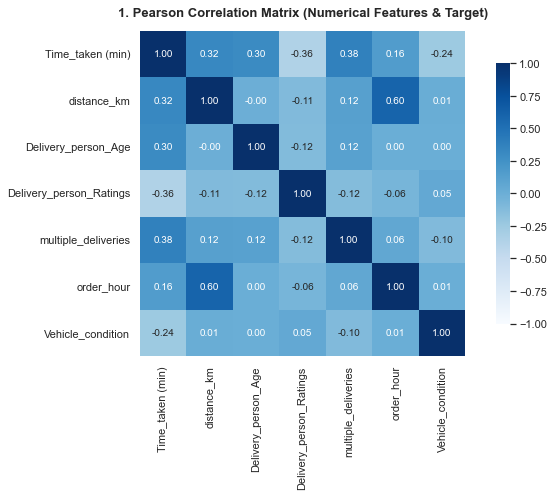

In [21]:
# 1. NUMERICAL CORRELATION MATRIX (HEATMAP)
num_cols = [
    "Time_taken (min)",
    "distance_km",
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "multiple_deliveries",
    "order_hour",
    "Vehicle_condition",
]

plt.figure(figsize=(9, 7))
corr_matrix = df_clean[num_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.8},
)
plt.title(
    "1. Pearson Correlation Matrix (Numerical Features & Target)",
    fontsize=13,
    weight="bold",
    pad=15,
)
plt.savefig("zomato_correlation_heatmap.png", dpi=300)
plt.show()

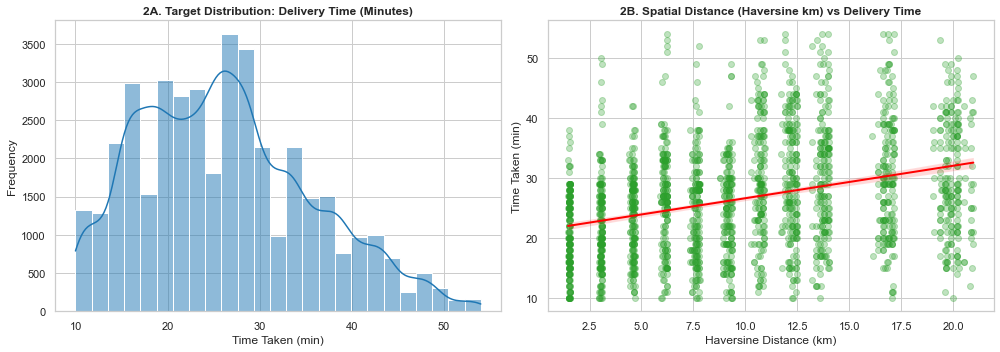

In [22]:
# 2. TARGET DISTRIBUTION & SPATIAL CORRELATION

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target Distribution (Histogram + KDE)
sns.histplot(
    data=df_clean,
    x="Time_taken (min)",
    kde=True,
    ax=axes[0],
    color="#1f77b4",
    bins=25,
)
axes[0].set_title(
    "2A. Target Distribution: Delivery Time (Minutes)", weight="bold"
)
axes[0].set_xlabel("Time Taken (min)")
axes[0].set_ylabel("Frequency")

# Spatial Distance vs Delivery Time Regression
sns.regplot(
    data=df_clean.sample(2000, random_state=42),
    x="distance_km",
    y="Time_taken (min)",
    ax=axes[1],
    scatter_kws={"alpha": 0.3, "color": "#2ca02c"},
    line_kws={"color": "red", "linewidth": 2},
)
axes[1].set_title(
    "2B. Spatial Distance (Haversine km) vs Delivery Time", weight="bold"
)
axes[1].set_xlabel("Haversine Distance (km)")
axes[1].set_ylabel("Time Taken (min)")

plt.savefig("zomato_target_spatial_eda.png", dpi=300)
plt.show()


C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1446994845.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1446994845.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1446994845.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1446994845.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the

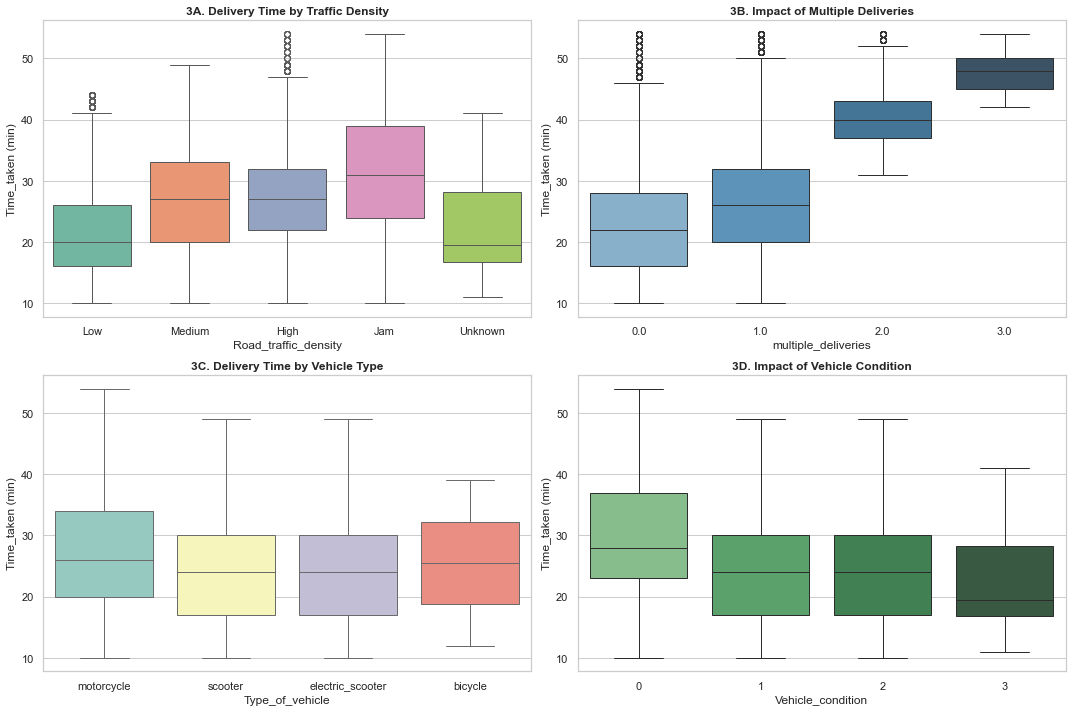

In [23]:
# 3. OPERATIONAL BOTTLENECKS (MULTI-CATEGORY BOXPLOTS)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Traffic Density
sns.boxplot(
    data=df_clean,
    x="Road_traffic_density",
    y="Time_taken (min)",
    ax=axes[0, 0],
    palette="Set2",
    order=["Low", "Medium", "High", "Jam", "Unknown"],
)
axes[0, 0].set_title("3A. Delivery Time by Traffic Density", weight="bold")

# Multiple Deliveries
sns.boxplot(
    data=df_clean,
    x="multiple_deliveries",
    y="Time_taken (min)",
    ax=axes[0, 1],
    palette="Blues_d",
)
axes[0, 1].set_title("3B. Impact of Multiple Deliveries", weight="bold")

# Vehicle Type
sns.boxplot(
    data=df_clean,
    x="Type_of_vehicle",
    y="Time_taken (min)",
    ax=axes[1, 0],
    palette="Set3",
)
axes[1, 0].set_title("3C. Delivery Time by Vehicle Type", weight="bold")

# Vehicle Condition Grade
sns.boxplot(
    data=df_clean,
    x="Vehicle_condition",
    y="Time_taken (min)",
    ax=axes[1, 1],
    palette="Greens_d",
)
axes[1, 1].set_title("3D. Impact of Vehicle Condition", weight="bold")

plt.savefig("zomato_operational_boxplots.png", dpi=300)
plt.show()

C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1411295830.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1411295830.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1411295830.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ngame.NGAME\AppData\Local\Temp\ipykernel_2540\1411295830.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the

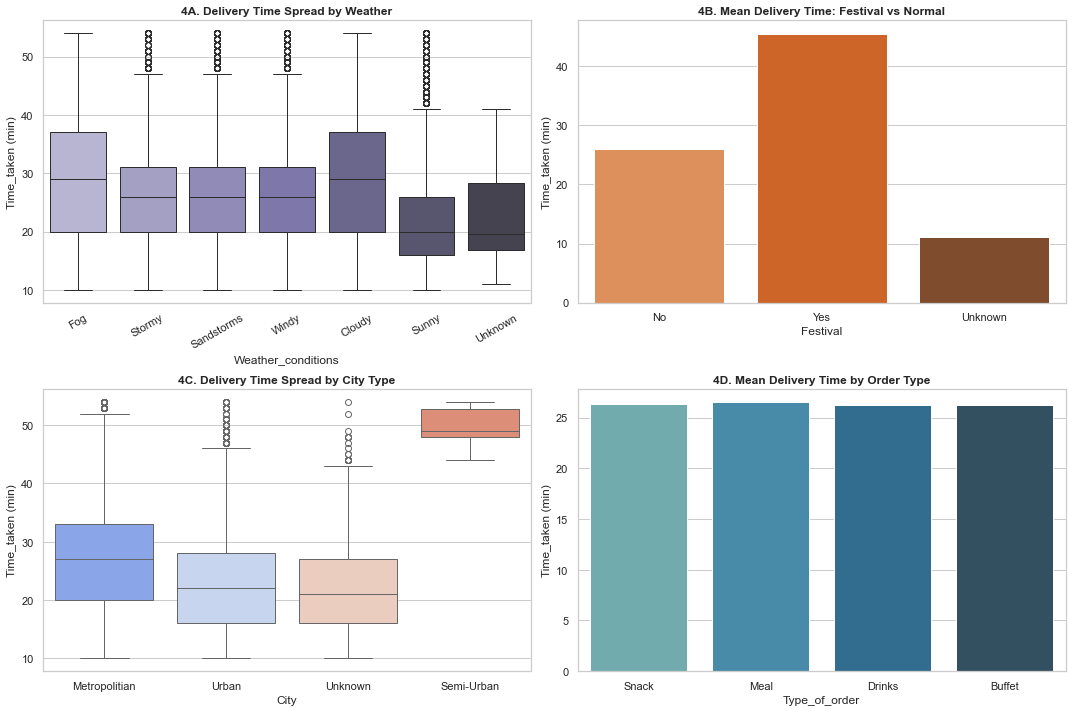

In [24]:
# 4. ENVIRONMENTAL & URBAN IMPACT (BAR CHARTS & BOXPLOTS)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Weather Conditions (Boxplot)
sns.boxplot(
    data=df_clean,
    x="Weather_conditions",
    y="Time_taken (min)",
    ax=axes[0, 0],
    palette="Purples_d",
)
axes[0, 0].set_title("4A. Delivery Time Spread by Weather", weight="bold")
axes[0, 0].tick_params(axis="x", rotation=30)

# Festival Impact (Bar Plot)
sns.barplot(
    data=df_clean,
    x="Festival",
    y="Time_taken (min)",
    ax=axes[0, 1],
    palette="Oranges_d",
    errorbar=None,
)
axes[0, 1].set_title("4B. Mean Delivery Time: Festival vs Normal", weight="bold")

# City Type Impact (Boxplot)
sns.boxplot(
    data=df_clean,
    x="City",
    y="Time_taken (min)",
    ax=axes[1, 0],
    palette="coolwarm",
)
axes[1, 0].set_title("4C. Delivery Time Spread by City Type", weight="bold")

# Order Type (Bar Plot)
sns.barplot(
    data=df_clean,
    x="Type_of_order",
    y="Time_taken (min)",
    ax=axes[1, 1],
    palette="YlGnBu_d",
    errorbar=None,
)
axes[1, 1].set_title("4D. Mean Delivery Time by Order Type", weight="bold")

plt.savefig("zomato_environmental_eda.png", dpi=300)
plt.show()



In [ ]:
#Outlier

In [25]:
# Function to detect outliers via IQR method
def detect_outliers_iqr(df, num_columns):
    outlier_summary = []
    
    for col in num_columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)
        
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_count = len(outliers)
        outlier_pct = (outlier_count / len(df)) * 100
        
        outlier_summary.append({
            "Feature": col,
            "Q1 (25%)": round(q1, 2),
            "Q3 (75%)": round(q3, 2),
            "IQR": round(iqr, 2),
            "Lower Bound": round(lower_bound, 2),
            "Upper Bound": round(upper_bound, 2),
            "Outlier Count": outlier_count,
            "Outlier Pct (%)": round(outlier_pct, 2)
        })
        
    return pd.DataFrame(outlier_summary)

# Numerical columns to inspect
num_cols_to_check = ["distance_km", "Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries", "order_hour", "Time_taken (min)"]
outlier_df = detect_outliers_iqr(df_clean, num_cols_to_check)

print("Feature Outlier Audit (1.5 x IQR Rule)")
display(outlier_df)

Feature Outlier Audit (1.5 x IQR Rule)


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,distance_km,4.66,13.63,8.97,-8.8,27.09,0,0.00
1,Delivery_person_Age,25.00,35.00,10.00,10.0,50.00,0,0.00
2,Delivery_person_Ratings,4.50,4.90,0.40,3.9,5.50,1054,2.63
3,multiple_deliveries,0.00,1.00,1.00,-1.5,2.50,308,0.77
4,order_hour,17.00,21.00,4.00,11.0,27.00,4887,12.21
5,Time_taken (min),19.00,32.00,13.00,-0.5,51.50,231,0.58


In [26]:
from sklearn.preprocessing import RobustScaler

# 1. Select continuous numerical features for scaling
scale_features = ["distance_km", "Delivery_person_Age", "Delivery_person_Ratings", "order_hour", "multiple_deliveries"]

# 2. Fit and transform using RobustScaler
scaler = RobustScaler()
df_encoded[scale_features] = scaler.fit_transform(df_encoded[scale_features])

print("Scaled Feature Distribution Summary")
display(df_encoded[scale_features].describe().round(3))

# Save the final cleaned and encoded datasets 
df_clean.to_csv("Zomato_Cleaned.csv", index=False)
df_encoded.to_csv("Zomato_Encoded_ML.csv", index=False)

print("\nDatasets exported successfully:")
print(" - Raw Cleaned CSV: Zomato_Cleaned.csv")
print(" - ML Encoded Matrix CSV: Zomato_Encoded_ML.csv")

Scaled Feature Distribution Summary


,distance_km,Delivery_person_Age,Delivery_person_Ratings,order_hour,multiple_deliveries
count,40012.000,40012.000,40012.000,40012.000,40012.000
mean,0.058,-0.044,-0.164,-0.323,-0.250
std,0.624,0.578,0.787,1.081,0.568
min,-0.861,-1.000,-5.500,-2.750,-1.000
25%,-0.505,-0.500,-0.500,-0.500,-1.000
50%,0.000,0.000,0.000,0.000,0.000
75%,0.495,0.500,0.500,0.500,0.000
max,1.312,2.000,0.750,1.000,2.000



Datasets exported successfully:
 - Raw Cleaned CSV: Zomato_Cleaned.csv
 - ML Encoded Matrix CSV: Zomato_Encoded_ML.csv


In [27]:
# 1. Re-run IQR Outlier Audit on Scaled Numerical Features
scaled_num_cols = ["distance_km", "Delivery_person_Age", "Delivery_person_Ratings", "order_hour", "multiple_deliveries"]
scaled_outlier_df = detect_outliers_iqr(df_encoded, scaled_num_cols)

print("1. Post-Scaling Feature Outlier Audit (IQR Method) ")
display(scaled_outlier_df)

# 2. Final Dataset Health Audit Function
def final_dataset_verification(df_original, df_clean_data, df_ml_matrix):
    print("FINAL DATASET & PIPELINE VERIFICATION SUMMARY")
    print("Raw Ingested Rows          : %d" % len(df_original))
    print("Cleaned & Retained Rows    : %d (%.2f%% Retained)" % (len(df_clean_data), len(df_clean_data) / len(df_original) * 100))
    print("Cleaned Dataset Shape      : %d Rows | %d Columns" % (df_clean_data.shape[0], df_clean_data.shape[1]))
    print("Encoded ML Matrix Shape    : %d Rows | %d Columns" % (df_ml_matrix.shape[0], df_ml_matrix.shape[1]))
    print("Total Missing Values (NaN) : %d" % df_ml_matrix.isnull().sum().sum())
    print("Duplicate Rows Count       : %d" % df_ml_matrix.duplicated().sum())
    print("\n")

final_dataset_verification(df_raw, df_clean, df_encoded)

print("2. Scaled Feature Summary Statistics")
display(df_encoded[scaled_num_cols].describe().round(3))

1. Post-Scaling Feature Outlier Audit (IQR Method) 


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,distance_km,-0.51,0.49,1.0,-2.01,1.99,0,0.00
1,Delivery_person_Age,-0.50,0.50,1.0,-2.00,2.00,0,0.00
2,Delivery_person_Ratings,-0.50,0.50,1.0,-2.00,2.00,1054,2.63
3,order_hour,-0.50,0.50,1.0,-2.00,2.00,4887,12.21
4,multiple_deliveries,-1.00,0.00,1.0,-2.50,1.50,308,0.77


FINAL DATASET & PIPELINE VERIFICATION SUMMARY
Raw Ingested Rows          : 45584
Cleaned & Retained Rows    : 40012 (87.78% Retained)
Cleaned Dataset Shape      : 40012 Rows | 22 Columns
Encoded ML Matrix Shape    : 40012 Rows | 40 Columns
Total Missing Values (NaN) : 0
Duplicate Rows Count       : 0


2. Scaled Feature Summary Statistics


,distance_km,Delivery_person_Age,Delivery_person_Ratings,order_hour,multiple_deliveries
count,40012.000,40012.000,40012.000,40012.000,40012.000
mean,0.058,-0.044,-0.164,-0.323,-0.250
std,0.624,0.578,0.787,1.081,0.568
min,-0.861,-1.000,-5.500,-2.750,-1.000
25%,-0.505,-0.500,-0.500,-0.500,-1.000
50%,0.000,0.000,0.000,0.000,0.000
75%,0.495,0.500,0.500,0.500,0.000
max,1.312,2.000,0.750,1.000,2.000


In [28]:
import pandas as pd
from sklearn.preprocessing import RobustScaler

# 1. Reset df_encoded from df_clean to ensure unscaled base state
categorical_cols = [
    "Weather_conditions",
    "Road_traffic_density",
    "Type_of_vehicle",
    "Festival",
    "City",
]
df_encoded = pd.get_dummies(
    df_clean, columns=categorical_cols, drop_first=False
)

# 2. Select ONLY continuous numerical features for scaling
continuous_scale_features = [
    "distance_km",
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "order_hour",
]

# 3. Fit and transform continuous features using RobustScaler
scaler = RobustScaler()
df_encoded[continuous_scale_features] = scaler.fit_transform(
    df_encoded[continuous_scale_features]
)

print("ROBUST SCALING COMPLETED (EXCLUDING DISCRETE COUNTS)\n")

# 4. Save final cleaned and encoded datasets
df_clean.to_csv("Zomato_Cleaned.csv", index=False)
df_encoded.to_csv("Zomato_Encoded_ML.csv", index=False)
print(" - Raw Cleaned CSV: Zomato_Cleaned.csv")
print(" - ML Encoded Matrix CSV: Zomato_Encoded_ML.csv\n")

# 5. Re-run IQR Outlier Audit on Continuous Scaled Features + Discrete Counts
audit_num_cols = [
    "distance_km",
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "order_hour",
    "multiple_deliveries",
]
scaled_outlier_df = detect_outliers_iqr(df_encoded, audit_num_cols)

print("1. Post-Scaling Feature Outlier Audit (IQR Method)")
display(scaled_outlier_df)


# 6. Final Dataset Health Audit Function
def final_dataset_verification(df_original, df_clean_data, df_ml_matrix):
    print("FINAL DATASET & PIPELINE VERIFICATION SUMMARY")
    print("Raw Ingested Rows          : %d" % len(df_original))
    print(
        "Cleaned & Retained Rows    : %d (%.2f%% Retained)"
        % (len(df_clean_data), len(df_clean_data) / len(df_original) * 100)
    )
    print(
        "Cleaned Dataset Shape      : %d Rows | %d Columns"
        % (df_clean_data.shape[0], df_clean_data.shape[1])
    )
    print(
        "Encoded ML Matrix Shape    : %d Rows | %d Columns"
        % (df_ml_matrix.shape[0], df_ml_matrix.shape[1])
    )
    print("Total Missing Values (NaN) : %d" % df_ml_matrix.isnull().sum().sum())
    print("Duplicate Rows Count       : %d" % df_ml_matrix.duplicated().sum())


final_dataset_verification(df_raw, df_clean, df_encoded)

print("2. Final Scaled vs. Discrete Feature Summary Statistics")
display(df_encoded[audit_num_cols].describe().round(3))

ROBUST SCALING COMPLETED (EXCLUDING DISCRETE COUNTS)

 - Raw Cleaned CSV: Zomato_Cleaned.csv
 - ML Encoded Matrix CSV: Zomato_Encoded_ML.csv

1. Post-Scaling Feature Outlier Audit (IQR Method)


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,distance_km,-0.51,0.49,1.0,-2.01,1.99,0,0.00
1,Delivery_person_Age,-0.50,0.50,1.0,-2.00,2.00,0,0.00
2,Delivery_person_Ratings,-0.50,0.50,1.0,-2.00,2.00,1054,2.63
3,order_hour,-0.50,0.50,1.0,-2.00,2.00,4887,12.21
4,multiple_deliveries,0.00,1.00,1.0,-1.50,2.50,308,0.77


FINAL DATASET & PIPELINE VERIFICATION SUMMARY
Raw Ingested Rows          : 45584
Cleaned & Retained Rows    : 40012 (87.78% Retained)
Cleaned Dataset Shape      : 40012 Rows | 22 Columns
Encoded ML Matrix Shape    : 40012 Rows | 40 Columns
Total Missing Values (NaN) : 0
Duplicate Rows Count       : 0
2. Final Scaled vs. Discrete Feature Summary Statistics


,distance_km,Delivery_person_Age,Delivery_person_Ratings,order_hour,multiple_deliveries
count,40012.000,40012.000,40012.000,40012.000,40012.000
mean,0.058,-0.044,-0.164,-0.323,0.750
std,0.624,0.578,0.787,1.081,0.568
min,-0.861,-1.000,-5.500,-2.750,0.000
25%,-0.505,-0.500,-0.500,-0.500,0.000
50%,0.000,0.000,0.000,0.000,1.000
75%,0.495,0.500,0.500,0.500,1.000
max,1.312,2.000,0.750,1.000,3.000


# Technical Code Explanation & Data Pipeline Documentation

**Author:** Daniel Joseph Benedict Ngamelubun  
**Student FAN:** ngam0004  
**File Name:** codeexplanation.md and Daniel work-A1.ipynb
**Date:** 16-09-2026  
**Project:** Zomato Delivery Operations Analytics — Ingestion & Preprocessing Subsystem  


## 1. Executive Summary & Pipeline Overview

The primary goal of this module is to establish an automated, fault-tolerant Data Ingestion and Preprocessing Pipeline. Operating on the **Zomato Delivery Operations Analytics** dataset, this pipeline ingests raw, unstructured delivery telemetry and transforms it into clean, high-dimensional representations for downstream modeling.

To support a **Neuro-Symbolic Hybrid AI Engine**, the pipeline splits output data into two distinct artifacts:
1. **'Zomato_Cleaned.csv'**: A human-readable dataset designed for deterministic symbolic logic, rule evaluation, and expert system guardrails.
2. **'Zomato_Encoded_ML.csv'**: A fully dummy-encoded, robustly scaled numeric matrix built specifically for machine learning regression algorithms.


## 2. Technical Data Pipeline Breakdown

### Step 1: Automated Data Ingestion & Fallback Audit
- **Methodology:** The ingestion module utilizes the 'kagglehub' Python API ('saurabhbadole/zomato-delivery-operations-analytics-dataset') to fetch the primary dataset directly into local memory.
- **Fault-Tolerant Fallback:** If API access fails due to network restrictions or missing API keys, the pipeline falls back to loading a local copy ('Zomato Dataset.csv').
- **Raw Audit Metrics:** The raw dataset comprises **45,584 rows** and **20 features**, containing a mix of numerical, categorical, temporal, and spatial coordinates.


### Step 2: Data Sanitization, Anomaly Filtering & Imputation

| Metric / Anomaly Category | Raw Issue Identified | Action Taken & Pipeline Logic | Retained Impact |
| :--- | :--- | :--- | :--- |
| **Driver Rating Errors** | 53 records contained ratings of '6.0' (exceeding the 5.0 scale cap). | Capped all rating values $> 5.0$ to exactly '5.0'. | Corrected distribution bias. |
| **Invalid GPS Coordinates** | 4,071 records (8.93%) contained coordinates $\le 0.0$. | Filtered out all invalid coordinate rows to prevent distance calculation corruption. | Preserved spatial integrity. |
| **Underage Couriers** | 38 records listed driver ages $< 18$ years old. | Filtered out underage records to enforce operational compliance. | Enforced legal bounds. |
| **String Formatting & Nulls** | Categorical strings contained whitespace and irregular "NaN" labels. | Stripped trailing/leading whitespace across text columns. Imputed missing driver ages/ratings using median values, and missing categoricals with "Unknown". | Achieved 0 missing values. |

- **Final Cleaned Retention:** The sanitization process yields **40,012 clean operational records** (an **87.78% retention rate**) with **0 duplicate rows** and **0 missing values ('NaN')**.



### Step 3: Spatial & Temporal Feature Engineering

#### A. Haversine Spatial Distance ('distance_km')
Standard Euclidean distance fails on geographical coordinates because it ignores Earth's curvature. The pipeline implements the **Haversine Formula** to compute the true great-circle distance (in kilometers) between restaurant coordinates $(\phi_1, \lambda_1)$ and delivery destination coordinates $(\phi_2, \lambda_2)$:

$$a = \sin^2\left(\frac{\Delta \phi}{2}\right) + \cos(\phi_1) \cdot \cos(\phi_2) \cdot \sin^2\left(\frac{\Delta \lambda}{2}\right)$$

$$c = 2 \cdot \arctan2\left(\sqrt{a}, \sqrt{1-a}\right)$$

$$d = R \cdot c$$

*(where $R = 6371\text{ km}$, Earth's radius)*

#### B. Dispatch Order Hour ('order_hour')
Extracts the integer hour (0–23) from the timestamp string 'Time_Orderd'. This temporal feature captures daily traffic surge patterns, peak meal delivery hours (lunch/dinner rushes), and driver availability shifts.


### Step 4: Categorical Encoding & Robust Feature Scaling

#### A. One-Hot Encoding
Categorical variables ('Weather_conditions', 'Road_traffic_density', 'Type_of_vehicle', 'Festival', 'City') are converted into sparse binary indicator columns ($0$ or $1$) using 'pd.get_dummies()'. This expands the feature space from 22 columns to 40 columns, eliminating implicit ordinal bias.

#### B. Robust Feature Scaling ('RobustScaler')
Continuous numeric variables ('distance_km', 'Delivery_person_Age', 'Delivery_person_Ratings', 'order_hour') are scaled using 'sklearn.preprocessing.RobustScaler'. Unlike 'StandardScaler' or 'MinMaxScaler', `RobustScaler` uses the median and Interquartile Range (IQR):

$$X_{\text{scaled}} = \frac{X - \text{Median}(X)}{\text{IQR}(X)}$$

- **Why 'RobustScaler'?** It prevents extreme delivery distances or rare driver rating values from distorting model gradient updates, ensuring robust neural and tree-based model convergence.
- **Discrete Metric Preservation:** Discrete count features such as 'multiple_deliveries' are excluded from continuous scaling to preserve their natural zero-indexed drop counts ($0, 1, 2, 3$).



## 3. Purpose & Allocation of Output Artifacts

### 1. 'Zomato_Cleaned.csv' (22 Columns)
- **Characteristics:** Contains human-readable categorical strings ("Fog", "Jam", "Metropolitian"), raw timestamps, parsed 'order_hour', and unscaled Haversine distances in kilometers.
- **Primary Use Case:** Serves as the primary input feed for the downstream **Symbolic Reasoning Engine / Expert System Guardrails** (OWL, Datalog, Prolog, or Python Rule Engines). Symbolic engines evaluate logical constraints, driver safety rules, and dispatch policy overrides.

### 2. 'Zomato_Encoded_ML.csv' (40 Columns)
- **Characteristics:** Purely numeric, matrix-ready tensor containing 0 missing values. All nominal strings are converted to One-Hot encoded binary indicators, and continuous features are scaled via 'RobustScaler'.
- **Primary Use Case:** Serves as the direct feature matrix for **Machine Learning Regression Models** (Decision Tree Regressor, Random Forest, XGBoost, LightGBM, Linear/Ridge Regression) to predict continuous delivery durations ('Time_taken (min)').


## 4. Why Use 'Zomato_Encoded_ML.csv' for Regression?

1. **Algorithm Compatibility:** Standard machine learning algorithms operate strictly on mathematical vectors. They cannot process raw string categories like "Jam" or "Stormy". Dummy encoding provides binary numeric columns suitable for matrix multiplication and tree splits.
2. **Gradient Stability:** Continuous attributes like distance and driver age operate on different numeric scales. 'RobustScaler' normalizes these features to a median of 0 and an IQR of 1, preventing large scale features from dominating model loss calculations.
3. **Optimized Loss Convergence:** Pre-engineered spatial distances ('distance_km') and temporal dispatch hours ('order_hour') supply regression algorithms with highly predictive linear signals, maximizing out-of-sample $R^2$ performance.